# Model XGBoost – prognoza popytu dla sklepów hurtowni mięsa

Notebook trenuje model XGBoost na zbiorze `Dane_sklepy.csv` (wynik notebooka 03), ocenia go na danych z 2025 roku, zapisuje prognozy i porównuje je z prognozami Random Forest (notebook 05).

W pierwszym etapie zaimportowano biblioteki niezbędne do przeprowadzenia analizy danych oraz budowy modelu prognostycznego. Biblioteka pandas została wykorzystana do przetwarzania danych tabelarycznych, natomiast numpy do wykonywania operacji numerycznych. Biblioteka matplotlib umożliwiła wizualizację wyników.

Do budowy modelu prognostycznego zastosowano bibliotekę xgboost, implementującą algorytm gradient boosting oparty na drzewach decyzyjnych. Dodatkowo wykorzystano funkcje z biblioteki scikit-learn służące do oceny jakości modelu (MAE, RMSE, R²) oraz do wyznaczenia permutacyjnej ważności cech.

**Załadowanie bibliotek oraz wczytanie wcześniej przygotowanego zbioru danych**

In [1]:
# Wczytanie bibliotek
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings('ignore')

# Wczytanie danych 
df = pd.read_csv(r'../dane/przetworzone/Dane_sklepy.csv', sep=';',decimal=',',encoding='utf-8-sig')


**Kodowanie wartości tekstowych na liczbowe**

Zmienne tekstowe, takie jak klient oraz podkategoria produktu, zostały zamienione na wartości liczbowe. Jest to wymagane, ponieważ wykorzystywany algorytm XGBoost pracuje wyłącznie na danych numerycznych.
Dla każdej zmiennej kategorii przypisano unikalny kod liczbowy za pomocą `cat.codes`. Słownik `mapowania` zapamiętuje przypisanie kodów, aby na końcu przywrócić oryginalne nazwy klientów i podkategorii.

In [2]:
# Zmiana wartości tekstowych na liczby - Kodowanie wartości
mapowania = {}
kolumny_tekstowe = ['Klient', 'Podkategoria']  

for col in kolumny_tekstowe:
    cat = df[col].astype('category')
    mapowania[col] = dict(enumerate(cat.cat.categories))
    df[col] = cat.cat.codes

print(df[['Klient', 'Podkategoria']].head())

df = df.sort_values(["data_sprzedaży","Podkategoria"])

   Klient  Podkategoria
0       0             0
1       0             0
2       0             0
3       0             0
4       0             0


**Sortowanie, ustawienie indexu (data), podział zbioru danych**

Dane zostały posortowane względem daty oraz podkategorii produktu. Kolejno ustawiono `data_sprzedaży` jako indeks, aby umożliwić chronologiczny podział danych (bez losowego mieszania – zapobiega to wyciekowi informacji z przyszłości).

**Podział danych na zbiory**
* Zbiór treningowy (2021–2023) – służy do nauki zależności na danych historycznych,
* Zbiór walidacyjny (2024) – służy do monitorowania jakości modelu i doboru liczby drzew (early stopping),
* Zbiór testowy (2025) – zbiór końcowy do oceny skuteczności modelu na danych, których model nie widział.

In [3]:
# Sortowanie i ustawienie indexu
df = df.sort_values(["data_sprzedaży","Podkategoria"])
df = df.set_index('data_sprzedaży')

df_model = df

# Podział zbioru danych
train = df_model.loc['2021-01-01':'2023-12-31']   # rok treningu
val   = df_model.loc['2024-01-01':'2024-12-31']   # rok walidacji
test  = df_model.loc['2025-01-01':'2025-12-31']   # rok testu 

print(f"Rozmiar zbiorów:")
print(f"Train: {train.shape[0]:,} wierszy")
print(f"Val: {val.shape[0]:,} wierszy")
print(f"Test: {test.shape[0]:,} wierszy")

Rozmiar zbiorów:
Train: 290,175 wierszy
Val: 96,990 wierszy
Test: 96,725 wierszy


**Grupowanie danych na zmienne cechy i cel**

Zmienną celu, czyli prognozowaną wartością, jest `Ilość` (dzienna sprzedaż w kg).
Pozostałe zmienne z listy `FEATURES` (20 cech: klient, podkategoria, cechy cykliczne i kalendarzowe, flagi sezonowe oraz `lag_364`) służą jako zmienne opisujące zjawisko sprzedaży.

Na tej podstawie przygotowano macierze cech `X` i wektory celu `y` dla zbioru treningowego, walidacyjnego i testowego.

In [4]:
FEATURES = ['Klient', 'Podkategoria',
            # Cykliczność
            'miesiac_sin','miesiac_cos', 
            'kwartał_sin', 'kwartał_cos', 
            'day_sin', 'day_cos',
            # Cechy kalendarza 
            'tydzien_roku', 'rok', 
            'czy_niedziela', 'okres_wielkanocny',
            'okres_wigilijny', 'czy_ferie_slask', 
            'czy_wakacje', 'czy_majowka','czy_swieto', 
            'dni_do_swieta', 'czy_szczyt_sklep', 
            # Lag
            'lag_364']

X_train = train[FEATURES]
y_train = train['Ilość']
y_val = val['Ilość']

X_val = val[FEATURES]

X_test = test[FEATURES]
y_test = test['Ilość']

**Definiowanie funkcji do oceny jakości modelu**

Funkcja `print_metrics` wylicza:
* **MAE** – średni błąd bezwzględny [kg],
* **RMSE** – pierwiastek błędu średniokwadratowego [kg], silniej karze duże pomyłki,
* **R²** – jaka część zmienności sprzedaży jest wyjaśniona przez model,
* **Bias** – średnia różnica *prognoza − rzeczywistość*; wartość ujemna oznacza niedoszacowanie popytu,
* **MAE / średnia** – błąd w odniesieniu do średniej sprzedaży,
* **WMAPE** – ważony procentowy błąd prognozy, liczony tylko dla dni ze sprzedażą większą od zera (dni zerowe zaburzają tę statystykę).

In [5]:
# Definiowanie parametrów badanych do oceny modelu 
def wmape(y_fact, y_pred):
    # Wykluczenie wartości 0 ponieważ zaburza statystykę 
    mask = y_fact > 0
    return np.sum(np.abs(y_fact[mask] - y_pred[mask])) / np.sum(y_fact[mask]) * 100

def print_metrics(name, y_fact, y_pred):

    mae  = mean_absolute_error(y_fact, y_pred)
    rmse = np.sqrt(mean_squared_error(y_fact, y_pred))
    r2   = r2_score(y_fact, y_pred)

    bias = np.mean(y_pred - y_fact)

    mean_ = y_fact.mean()
    wm    = wmape(y_fact.values, y_pred)

    print(f"\n{'─'*20}")
    print(f"  {name}")
    print(f"{'─'*20}")
    print(f"MAE           : {mae:.4f} kg")
    print(f"RMSE          : {rmse:.4f} kg")
    print(f"R²            : {r2:.4f}")
    print(f"Bias          : {bias:.4f} kg")
    print(f"Średnia       : {mean_:.4f} kg")
    print(f"MAE / średnia : {mae/mean_*100:.1f}%")
    print(f"WMAPE         : {wm:.1f}%")

    return mae, rmse, r2, bias

**Budowa modelu XGBoost**

Do stworzenia prognozy wykorzystano model XGBRegressor z funkcją celu `reg:tweedie`, która dobrze radzi sobie z danymi sprzedażowymi, gdzie występuje dużo wartości zerowych oraz dodatnie wartości ciągłe. Złożoność modelu ograniczono płytkimi drzewami (`max_depth=4`), małym krokiem uczenia (`learning_rate=0.02`) oraz regularyzacją L1/L2. Zastosowano również parametr `early_stopping_rounds`, który pozwala dobrać odpowiednią liczbę drzew – trening na latach 2021–2023 zatrzymuje się, gdy przez 50 iteracji wynik na zbiorze walidacyjnym 2024 się nie poprawia.

In [ ]:
params = dict(
    n_estimators = 2000,            # liczba drzew
    max_depth = 4,                  # maksymalna głębokość drzewa
    learning_rate = 0.02,           # szybkość uczenia 
    objective = 'reg:tweedie',      # funkcja celu dla regresji z rozkładem Tweediego
    tweedie_variance_power = 1.6,   # parametr rozkładu Tweediego; określa wariancję względem średniej
    tree_method = 'hist',           # sposób budowania drzew; 'hist' wykorzystuje histogramy i jest szybki
    random_state = 42,              # losowość
    reg_alpha = 1,                  # regularyzacja L1; pomaga ograniczać złożoność modelu
    reg_lambda = 10,                # regularyzacja L2; pomaga ograniczać złożoność modelu
    early_stopping_rounds = 50)     # zatrzymuje trening, jeśli przez 50 iteracji nie ma poprawy na zbiorze walidacyjnym      

In [7]:
# Dobrór parametrów i użycie early stopping aby model wybrał liczbę drzew 

print("Trening 2021–2023, Early stopping na zbiorze walidacyjnym 2024")

reg = xgb.XGBRegressor(**params)

reg.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False)


najlepsza_liczba_drzew = reg.best_iteration + 1
print(f"Najlepsza liczba drzew: {najlepsza_liczba_drzew}")

# Metryki na walidacji
pred_val = reg.predict(X_val).clip(0)

mae_val, rmse_val, r2_val, bias_val = print_metrics("WALIDACJA 2024", y_val, pred_val)

Trening 2021–2023, Early stopping na zbiorze walidacyjnym 2024
Najlepsza liczba drzew: 1167

────────────────────
  WALIDACJA 2024
────────────────────
MAE           : 1.5150 kg
RMSE          : 7.8226 kg
R²            : 0.4202
Bias          : -0.3882 kg
Średnia       : 1.6185 kg
MAE / średnia : 93.6%
WMAPE         : 67.5%


**Model końcowy i test na danych z 2025 roku**

Zbiór treningowy i walidacyjny (2021–2024) zostały połączone, a model końcowy wytrenowano z liczbą drzew wyznaczoną wcześniej przez early stopping (parametr `early_stopping_rounds` jest usuwany, bo model końcowy nie ma już zbioru walidacyjnego). Ujemne prognozy obcinane są do 0, a wartości poniżej 0,01 kg zaokrąglane do 0. Skuteczność oceniono na zbiorze testowym 2025.

In [8]:
# TRAIN+VAL, TEST NA 2025
# Użyte zostaje najlepsza_liczba_drzew z pierwszego modelu 

print("Trening na 2021–2024, Test końcowy na zbiorze danych 2025")

# Połączenie zbioru treningowego i validacyjnego

X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])
 
 
params_final = params.copy()
params_final["n_estimators"] = najlepsza_liczba_drzew

# Usunięcie parametru early_stopping_rounds
params_final.pop("early_stopping_rounds")

# Tworzenie modelu końcowego  
reg_final = xgb.XGBRegressor(**params_final)

# Trenowanie
reg_final.fit(X_train_full, y_train_full, verbose=False)

# Predykcja na zbiorze testowym
pred_test = np.clip(reg_final.predict(X_test), 0, None)
pred_test = np.where(pred_test < 0.01, 0, pred_test)

# Metryki na teście
mae_test, rmse_test, r2_test, bias_test = print_metrics("TEST 2025", y_test, pred_test)

# Zapisanie prognozy
test = test.copy()
test["Prognoza"] = pred_test
test["Rzeczywista"] = y_test.values

Trening na 2021–2024, Test końcowy na zbiorze danych 2025

────────────────────
  TEST 2025
────────────────────
MAE           : 1.6500 kg
RMSE          : 7.6519 kg
R²            : 0.4928
Bias          : -0.3548 kg
Średnia       : 1.8155 kg
MAE / średnia : 90.9%
WMAPE         : 63.4%


**Analiza ważności cech**

Wbudowana ważność cech XGBoost dla modelu końcowego. Najważniejsze okazały się flaga `czy_niedziela` (w niedziele sprzedaż wynosi 0) oraz `lag_364`. Druga komórka wyświetla pełną listę 20 cech.

In [9]:
xgb_importance = pd.DataFrame({
    'Cecha': X_train_full.columns,
    'Ważność': reg_final.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Ważność',
    ascending=False
)
print('Analiza ważności cech dla XGBoost / Sklepów')
print(xgb_importance.head(10))

Analiza ważności cech dla XGBoost / Sklepów
               Cecha   Ważność
10     czy_niedziela  0.385583
19           lag_364  0.211447
16        czy_swieto  0.074280
1       Podkategoria  0.069798
7            day_cos  0.049049
0             Klient  0.033066
6            day_sin  0.030630
18  czy_szczyt_sklep  0.028109
2        miesiac_sin  0.017496
17     dni_do_swieta  0.015801


In [10]:
importance = pd.DataFrame({
    "Cecha": X_train_full.columns,
    "Ważność": reg_final.feature_importances_
})

importance = importance.sort_values(
    "Ważność",
    ascending=False
)

print(importance.head(20))

                Cecha   Ważność
10      czy_niedziela  0.385583
19            lag_364  0.211447
16         czy_swieto  0.074280
1        Podkategoria  0.069798
7             day_cos  0.049049
0              Klient  0.033066
6             day_sin  0.030630
18   czy_szczyt_sklep  0.028109
2         miesiac_sin  0.017496
17      dni_do_swieta  0.015801
12    okres_wigilijny  0.015655
11  okres_wielkanocny  0.013394
3         miesiac_cos  0.012098
9                 rok  0.011324
14        czy_wakacje  0.009220
5         kwartał_cos  0.008125
8        tydzien_roku  0.005252
4         kwartał_sin  0.004590
13    czy_ferie_slask  0.003743
15        czy_majowka  0.001341


**Obliczenie błędów prognozy i odkodowanie zmiennych tekstowych**

Dla każdego wiersza liczony jest błąd (prognoza − rzeczywistość) oraz błąd bezwzględny, dodawane są etykiety modelu i segmentu, a kody klientów i podkategorii zamieniane są z powrotem na nazwy. Wynik zapisywany jest do `../wyniki/prognozy/XGB_SKLEP_Prognoza_2025.csv` w celu dalszej analizy w Power BI.

In [11]:
test["Model"] = "XGBoost"
test["Segment"] = "Sklepy"

In [12]:
test["Błąd"] = test["Prognoza"] - test["Rzeczywista"]
test["Błąd_abs"] = abs(test["Błąd"])

In [13]:
# Przywrócenie nazw sklepów i podkategorii
test["Klient_nazwa"] = test["Klient"].map(mapowania["Klient"])
test["Podkategoria_nazwa"] = test["Podkategoria"].map(mapowania["Podkategoria"])

In [14]:
test.reset_index(inplace=True)

In [15]:
test.head()

,data_sprzedaży,Klient,Podkategoria,Ilość,miesiac_sin,miesiac_cos,kwartał_sin,kwartał_cos,day_sin,day_cos,...,czy_szczyt_sklep,lag_364,Prognoza,Rzeczywista,Model,Segment,Błąd,Błąd_abs,Klient_nazwa,Podkategoria_nazwa
0,2025-01-01,0,0,0.0,0.5,0.866025,1.0,6.123234e-17,0.974928,-0.222521,...,0,0.00,0.0,0.0,XGBoost,Sklepy,0.0,0.0,S1,Balerony i Karczki
1,2025-01-01,1,0,0.0,0.5,0.866025,1.0,6.123234e-17,0.974928,-0.222521,...,0,0.00,0.0,0.0,XGBoost,Sklepy,0.0,0.0,S2,Balerony i Karczki
2,2025-01-01,2,0,0.0,0.5,0.866025,1.0,6.123234e-17,0.974928,-0.222521,...,0,4.11,0.0,0.0,XGBoost,Sklepy,0.0,0.0,S3,Balerony i Karczki
3,2025-01-01,3,0,0.0,0.5,0.866025,1.0,6.123234e-17,0.974928,-0.222521,...,0,0.00,0.0,0.0,XGBoost,Sklepy,0.0,0.0,S4,Balerony i Karczki
4,2025-01-01,4,0,0.0,0.5,0.866025,1.0,6.123234e-17,0.974928,-0.222521,...,0,0.00,0.0,0.0,XGBoost,Sklepy,0.0,0.0,S5,Balerony i Karczki


In [16]:
xgb_sklep = test[['data_sprzedaży','Prognoza', 'Model',
       'Segment', 'Rzeczywista', 'Błąd', 'Błąd_abs', 'Klient_nazwa','Podkategoria_nazwa']]

In [17]:

xgb_sklep.to_csv(
    r"../wyniki/prognozy/XGB_SKLEP_Prognoza_2025.csv",
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig"
)

**Porównanie prognoz Random Forest i XGBoost**

Wczytywane są zapisane prognozy obu modeli na 2025 rok (plik `prognozy_RF_2025.csv` pochodzi z notebooka 05, więc musi on zostać uruchomiony wcześniej). Kolumny prognoz i błędów otrzymują sufiksy `_RF` / `_XGB`, a tabele łączone są po dacie, segmencie, kliencie, podkategorii i wartości rzeczywistej. Dodatkowo liczona jest różnica prognoz RF − XGB. Wynik zapisywany jest do `../wyniki/prognozy/Porownanie_RF_XGB_2025.csv` (do analizy w Power BI).

In [ ]:
import pandas as pd

rf = pd.read_csv(
    r"../wyniki/prognozy/prognozy_RF_2025.csv",
    sep=";"
)

xgb = pd.read_csv(
    r"../wyniki/prognozy/XGB_SKLEP_Prognoza_2025.csv",
    sep=";"
)

In [20]:
rf = rf.rename(columns={
    "Prognoza": "Prognoza_RF",
    "Błąd": "Błąd_RF",
    "Błąd_abs": "Błąd_abs_RF"
})

xgb = xgb.rename(columns={
    "Prognoza": "Prognoza_XGB",
    "Błąd": "Błąd_XGB",
    "Błąd_abs": "Błąd_abs_XGB"
})

In [21]:
porownanie = rf.merge(
    xgb[[
        "data_sprzedaży",
        "Segment",
        "Rzeczywista",
        "Klient_nazwa",
        "Podkategoria_nazwa",
        "Prognoza_XGB",
        "Błąd_XGB",
        "Błąd_abs_XGB"
    ]],
    on=[
        "data_sprzedaży",
        "Segment",
        "Rzeczywista",
        "Klient_nazwa",
        "Podkategoria_nazwa"
    ],
    how="inner"
)
for col in ["Prognoza_RF", "Prognoza_XGB"]:
    porownanie[col] = (
        porownanie[col]
        .astype(str)
        .str.replace(",", ".", regex=False)
    )
    porownanie[col] = pd.to_numeric(porownanie[col], errors="coerce")

porownanie["Różnica_prognoz_RF_minus_XGB"] = (
    porownanie["Prognoza_RF"] - porownanie["Prognoza_XGB"]
)

In [29]:
porownanie.to_csv(
    r"../wyniki/prognozy/Porownanie_RF_XGB_2025.csv",
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig"
)

**Analiza błędów prognozy XGBoost (test 2025)**

Przygotowanie tabeli `test_eval` z prognozą, wartością rzeczywistą i błędem, a następnie:
* wykres sprzedaży rzeczywistej i prognozowanej w czasie,
* 30 największych błędów prognozy (klient, podkategoria),
* wyniki dla poszczególnych sklepów (suma rzeczywista i prognozowana, MAE, Bias, WMAPE).

In [23]:
test_eval = test.copy()
test_eval["Rzeczywista"] = y_test.values
test_eval["Prognoza"] = pred_test
test_eval["Błąd"] = test_eval["Prognoza"] - test_eval["Rzeczywista"]
test_eval["Błąd_abs"] = abs(test_eval["Błąd"])

In [24]:
test_eval["Klient_nazwa"] = test_eval["Klient"].map(mapowania["Klient"])
test_eval["Podkategoria_nazwa"] = (test_eval["Podkategoria"].map(mapowania["Podkategoria"]))

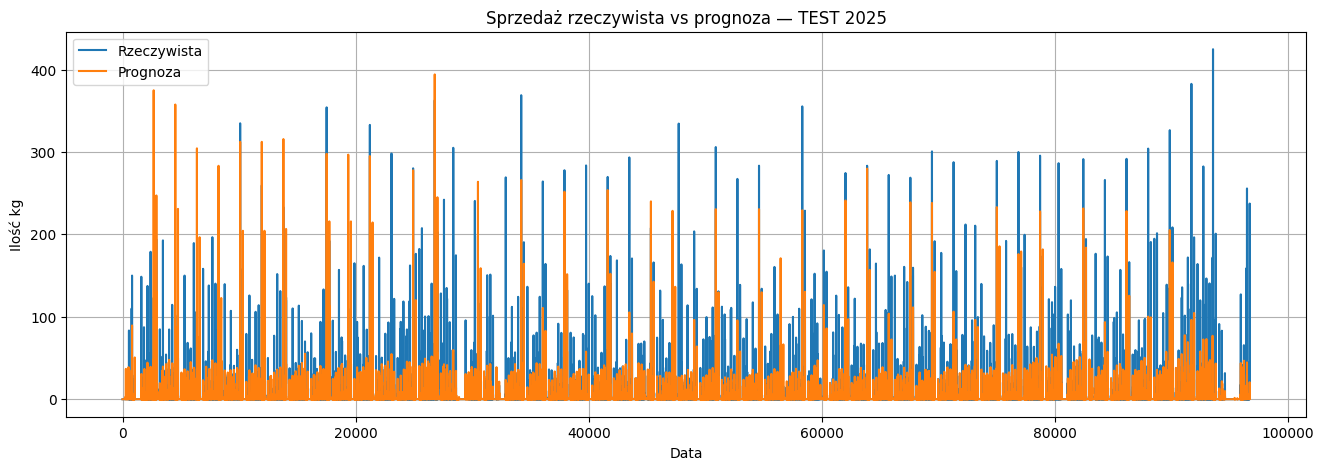

In [25]:
# Prognoza vs rzeczywista sprzedaż w czasie

daily = test_eval.groupby(test_eval.index)[["Rzeczywista", "Prognoza"]].sum()

plt.figure(figsize=(16,5))
plt.plot(daily.index, daily["Rzeczywista"], label="Rzeczywista")
plt.plot(daily.index, daily["Prognoza"], label="Prognoza")
plt.title("Sprzedaż rzeczywista vs prognoza — TEST 2025")
plt.xlabel("Data")
plt.ylabel("Ilość kg")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
najwieksze_bledy = test_eval.sort_values("Błąd_abs", ascending=False)

najwieksze_bledy[
    ["Klient_nazwa", "Podkategoria_nazwa", "Rzeczywista", "Prognoza", "Błąd", "Błąd_abs"]
].head(30)

,Klient_nazwa,Podkategoria_nazwa,Rzeczywista,Prognoza,Błąd,Błąd_abs
93569,S5,Drób,424.64,59.569084,-365.070916,365.070916
47724,S5,Drób,334.41,3.186606,-331.223394,331.223394
4529,S5,Drób,60.45,357.530426,297.080426,297.080426
91714,S5,Drób,382.61,96.267296,-286.342704,286.342704
8239,S5,Drób,0.00,283.197327,283.197327,283.197327
92738,S4,Wieprzowina,282.42,21.121164,-261.298836,261.298836
2674,S5,Drób,123.12,374.822357,251.702357,251.702357
32883,S4,Drób,269.17,23.395189,-245.774811,245.774811
28379,S5,Drób,305.03,59.590080,-245.439920,245.439920
23079,S5,Drób,298.14,54.810402,-243.329598,243.329598


In [27]:
sklepy_wynik = test_eval.groupby("Klient").apply(
    lambda x: pd.Series({
        "Rzeczywista": x["Rzeczywista"].sum(),
        "Prognoza": x["Prognoza"].sum(),
        "MAE": mean_absolute_error(x["Rzeczywista"], x["Prognoza"]),
        "Bias": (x["Prognoza"] - x["Rzeczywista"]).mean(),
        "WMAPE": np.sum(abs(x["Rzeczywista"] - x["Prognoza"])) / np.sum(x["Rzeczywista"]) * 100
    })
)

sklepy_wynik

,Rzeczywista,Prognoza,MAE,Bias,WMAPE
Klient,,,,,
0,10835.18,9052.960938,0.664416,-0.092128,118.624103
1,43901.81,38395.386719,1.716010,-0.284643,75.614692
2,19831.00,27301.601562,1.099720,0.386177,107.276896
3,57048.35,27459.445312,2.765271,-1.529538,93.769871
4,43990.39,39074.585938,2.004692,-0.254112,88.157358


**Permutacyjna ważność cech (Permutation Importance)**

Dla porównania z wbudowaną ważnością cech obliczono ważność permutacyjną na zbiorze testowym 2025: wartości każdej cechy są losowo mieszane (10 powtórzeń) i mierzony jest wzrost błędu MAE. W tej metodzie najważniejsze okazały się podkategoria i klient, a w dalszej kolejności dzień tygodnia (`day_sin`) i `lag_364`.

In [28]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    reg_final,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print("Najważniejsze cechy Permutation Importance na test 2025:")
print("Model XGBoost")
print(perm_importance.head(15))



Najważniejsze cechy Permutation Importance na test 2025:
Model XGBoost
Podkategoria         0.691539
Klient               0.365410
day_sin              0.177452
lag_364              0.174570
czy_niedziela        0.116030
czy_swieto           0.052546
day_cos              0.033347
dni_do_swieta        0.021615
tydzien_roku         0.007940
okres_wielkanocny    0.007800
okres_wigilijny      0.000840
czy_majowka          0.000009
rok                  0.000000
czy_ferie_slask     -0.000078
kwartał_cos         -0.000145
dtype: float64


**Wizualizacja prognozy**

* Prognoza i rzeczywista sprzedaż w 2025 roku dla wybranego klienta i podkategorii (S5 – Wołowina i Cielęcina),
* średnia dzienna sprzedaż rzeczywista i prognozowana według dnia tygodnia.

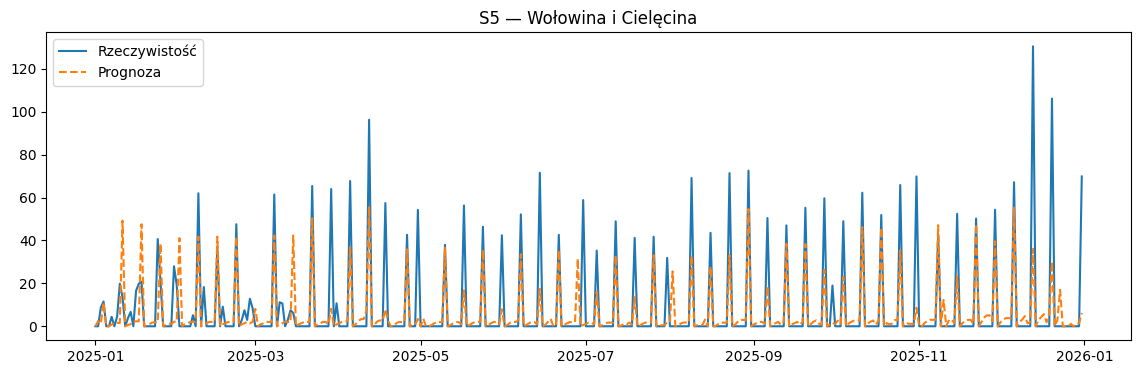

In [ ]:
import matplotlib.pyplot as plt

klient = 'S5'
produkt = 'Wołowina i Cielęcina'

maska = (
    (test['Klient_nazwa'] == klient) & 
    (test['Podkategoria_nazwa'] == produkt)
)

dane = test[maska].sort_index()

plt.figure(figsize=(14, 4))
plt.plot(dane.index, dane['Ilość'], label='Rzeczywistość')
plt.plot(dane.index, dane['Prognoza'], label='Prognoza', linestyle='--')
plt.title(f'{klient} — {produkt}')
plt.legend()
plt.show()

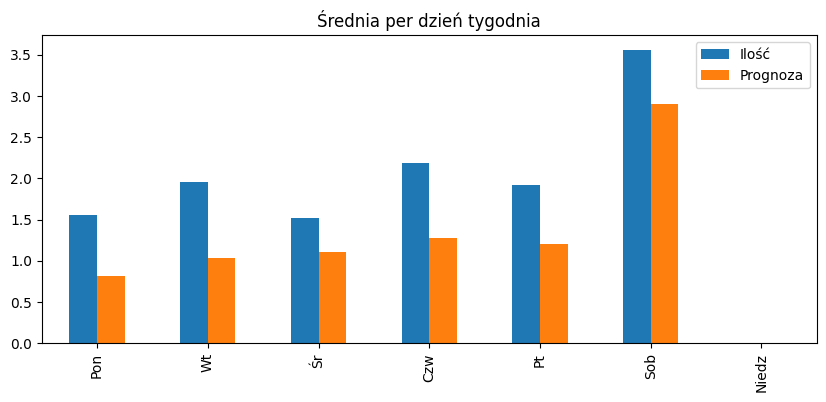

In [ ]:
test['dzien'] = test.index.dayofweek
dziennie = test.groupby('dzien')[['Ilość', 'Prognoza']].mean().round(2)
dziennie.index = ['Pon', 'Wt', 'Śr', 'Czw', 'Pt', 'Sob', 'Niedz']

dziennie.plot(kind='bar', figsize=(10, 4), title='Średnia per dzień tygodnia')
plt.show()